# 🌳 Decision Tree from Scratch

A Decision Tree is a **tree-structured classifier** that splits the data repeatedly based on feature values, forming a set of if-else rules that lead to a final prediction. It's one of the most interpretable ML models — you can literally read off the decision-making logic.

## 📖 What You'll Learn
1. The intuition behind Decision Trees
2. Impurity measures: Gini Impurity and Entropy
3. Information Gain and how the best split is chosen
4. Implementing a Decision Tree **from scratch** using only NumPy
5. Comparing our implementation with scikit-learn's `DecisionTreeClassifier`
6. The effect of `max_depth` on overfitting (bias-variance tradeoff)
7. Evaluating with accuracy, confusion matrix, and classification report
8. Visualizing the tree structure and decision boundaries

## 📊 Dataset
We'll use the **[Iris dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset)**, the same classic multi-class dataset used in the KNN notebook, so we can compare model behavior on familiar data.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")
np.random.seed(42)

## 2. Load and Explore the Dataset

In [2]:
data = load_iris()
X = data.data
y = data.target
feature_names = data.feature_names

df = pd.DataFrame(X, columns=feature_names)
df['species'] = pd.Categorical.from_codes(y, data.target_names)

print("Shape of dataset:", X.shape)
print("Classes:", data.target_names)
df.head()

Shape of dataset: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. The Math Behind Decision Trees

### 3.1 Impurity Measures

A good split is one that produces "pure" groups — subsets that mostly contain a single class. We measure impurity using:

**Gini Impurity**:

$$
Gini = 1 - \sum_{i=1}^{C} p_i^2
$$

**Entropy**:

$$
Entropy = -\sum_{i=1}^{C} p_i \log_2(p_i)
$$

where $p_i$ is the proportion of class $i$ in the node. Both reach **0** for a perfectly pure node and are maximized when classes are evenly mixed.

### 3.2 Information Gain

To decide the best feature and threshold to split on, we calculate the **Information Gain** — how much impurity decreases after the split:

$$
IG = Impurity_{parent} - \left(\frac{n_{left}}{n}Impurity_{left} + \frac{n_{right}}{n}Impurity_{right}\right)
$$

### 3.3 Building the Tree

The algorithm works **recursively**:
1. At each node, try every feature and every possible threshold.
2. Pick the split that maximizes Information Gain.
3. Split the data into left/right children.
4. Repeat recursively on each child until a stopping condition is met (e.g. max depth reached, node is pure, or too few samples remain).
5. Leaf nodes store the majority class as the prediction.

## 4. Implementing a Decision Tree from Scratch

In [3]:
class Node:
    """A single node in the tree -- either a decision node or a leaf."""
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature      # index of feature used to split
        self.threshold = threshold  # threshold value used to split
        self.left = left            # left child (Node)
        self.right = right          # right child (Node)
        self.value = value          # class label, only set for leaf nodes

    def is_leaf(self):
        return self.value is not None

In [4]:
class DecisionTreeScratch:
    def __init__(self, max_depth=5, min_samples_split=2, criterion='gini'):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion
        self.root = None

    # ---------- Impurity ----------
    def _gini(self, y):
        counts = np.bincount(y)
        probabilities = counts / len(y)
        return 1 - np.sum(probabilities ** 2)

    def _entropy(self, y):
        counts = np.bincount(y)
        probabilities = counts / len(y)
        probabilities = probabilities[probabilities > 0]  # avoid log(0)
        return -np.sum(probabilities * np.log2(probabilities))

    def _impurity(self, y):
        return self._entropy(y) if self.criterion == 'entropy' else self._gini(y)

    # ---------- Finding the best split ----------
    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        best_gain = -1
        best_feature, best_threshold = None, None
        parent_impurity = self._impurity(y)

        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])
            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask

                if left_mask.sum() == 0 or right_mask.sum() == 0:
                    continue

                n_left, n_right = left_mask.sum(), right_mask.sum()
                impurity_left = self._impurity(y[left_mask])
                impurity_right = self._impurity(y[right_mask])

                weighted_impurity = (n_left / n_samples) * impurity_left + \
                                     (n_right / n_samples) * impurity_right
                gain = parent_impurity - weighted_impurity

                if gain > best_gain:
                    best_gain = gain
                    best_feature = feature
                    best_threshold = threshold

        return best_feature, best_threshold, best_gain

    # ---------- Recursive tree building ----------
    def _build_tree(self, X, y, depth=0):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        # Stopping conditions -> create a leaf
        if (depth >= self.max_depth or
            n_classes == 1 or
            n_samples < self.min_samples_split):
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        feature, threshold, gain = self._best_split(X, y)

        # No split improves purity -> create a leaf
        if feature is None or gain <= 0:
            leaf_value = Counter(y).most_common(1)[0][0]
            return Node(value=leaf_value)

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=feature, threshold=threshold, left=left_child, right=right_child)

    def fit(self, X, y):
        X, y = np.array(X), np.array(y)
        self.root = self._build_tree(X, y)
        return self

    # ---------- Prediction ----------
    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        else:
            return self._traverse(x, node.right)

    def predict(self, X):
        X = np.array(X)
        return np.array([self._traverse(x, self.root) for x in X])

    # ---------- Printing the tree ----------
    def print_tree(self, node=None, depth=0, feature_names=None):
        if node is None:
            node = self.root
        indent = "  " * depth
        if node.is_leaf():
            print(f"{indent}Predict -> class {node.value}")
        else:
            fname = feature_names[node.feature] if feature_names is not None else f"X[{node.feature}]"
            print(f"{indent}if {fname} <= {node.threshold:.2f}:")
            self.print_tree(node.left, depth + 1, feature_names)
            print(f"{indent}else:")
            self.print_tree(node.right, depth + 1, feature_names)

## 5. Train / Test Split

Note: unlike Logistic Regression or KNN, Decision Trees **don't require feature scaling** — splits are based on thresholds per feature, independent of scale.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 6. Train Our Scratch Model

In [6]:
model = DecisionTreeScratch(max_depth=3, criterion='gini')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy (Scratch Model, max_depth=3):", accuracy_score(y_test, y_pred))

Accuracy (Scratch Model, max_depth=3): 0.9666666666666667


### 6.1 Reading the Tree

One of the biggest advantages of Decision Trees is interpretability — we can print the exact rules it learned.

In [7]:
model.print_tree(feature_names=feature_names)

if petal length (cm) <= 1.90:
  Predict -> class 0
else:
  if petal width (cm) <= 1.60:
    if petal length (cm) <= 4.90:
      Predict -> class 1
    else:
      Predict -> class 2
  else:
    if petal length (cm) <= 4.80:
      Predict -> class 2
    else:
      Predict -> class 2


## 7. Effect of `max_depth` on Overfitting

Let's see how tree depth affects training vs. test accuracy — a classic bias-variance tradeoff.

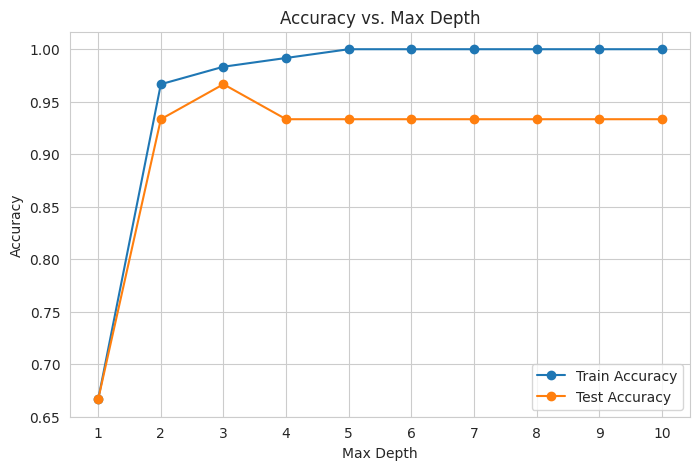

In [8]:
depths = range(1, 11)
train_acc, test_acc = [], []

for d in depths:
    tree = DecisionTreeScratch(max_depth=d)
    tree.fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, tree.predict(X_train)))
    test_acc.append(accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, marker='o', label='Train Accuracy')
plt.plot(depths, test_acc, marker='o', label='Test Accuracy')
plt.title("Accuracy vs. Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.xticks(list(depths))
plt.legend()
plt.show()

## 8. Model Evaluation

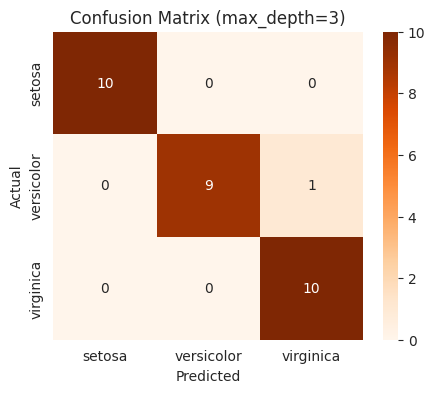

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Confusion Matrix (max_depth=3)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

## 9. Comparing with Scikit-learn's DecisionTreeClassifier

Let's verify our from-scratch implementation against the industry-standard library.

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

sk_model = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
sk_model.fit(X_train, y_train)
sk_pred = sk_model.predict(X_test)

print("Accuracy (Scratch Model):   ", accuracy_score(y_test, y_pred))
print("Accuracy (Scikit-learn):    ", accuracy_score(y_test, sk_pred))

Accuracy (Scratch Model):    0.9666666666666667
Accuracy (Scikit-learn):     0.9666666666666667


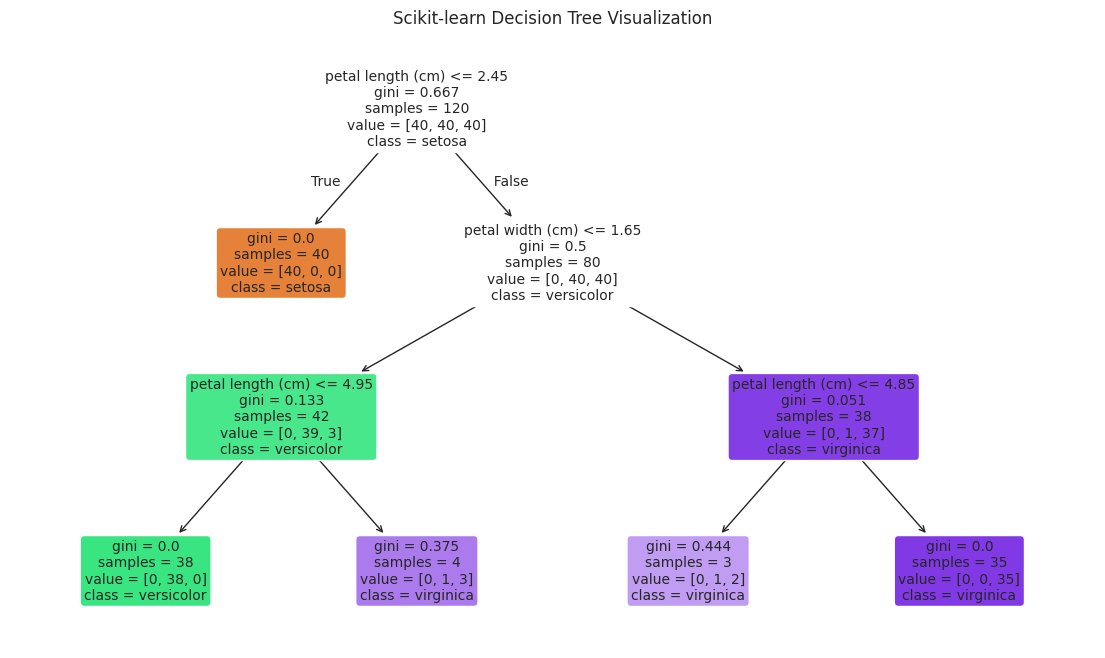

In [11]:
plt.figure(figsize=(14, 8))
plot_tree(sk_model, feature_names=feature_names, class_names=data.target_names,
          filled=True, rounded=True, fontsize=10)
plt.title("Scikit-learn Decision Tree Visualization")
plt.show()

## 10. Visualizing Decision Boundaries

To visualize the decision boundary, we use just 2 features (petal length & width).

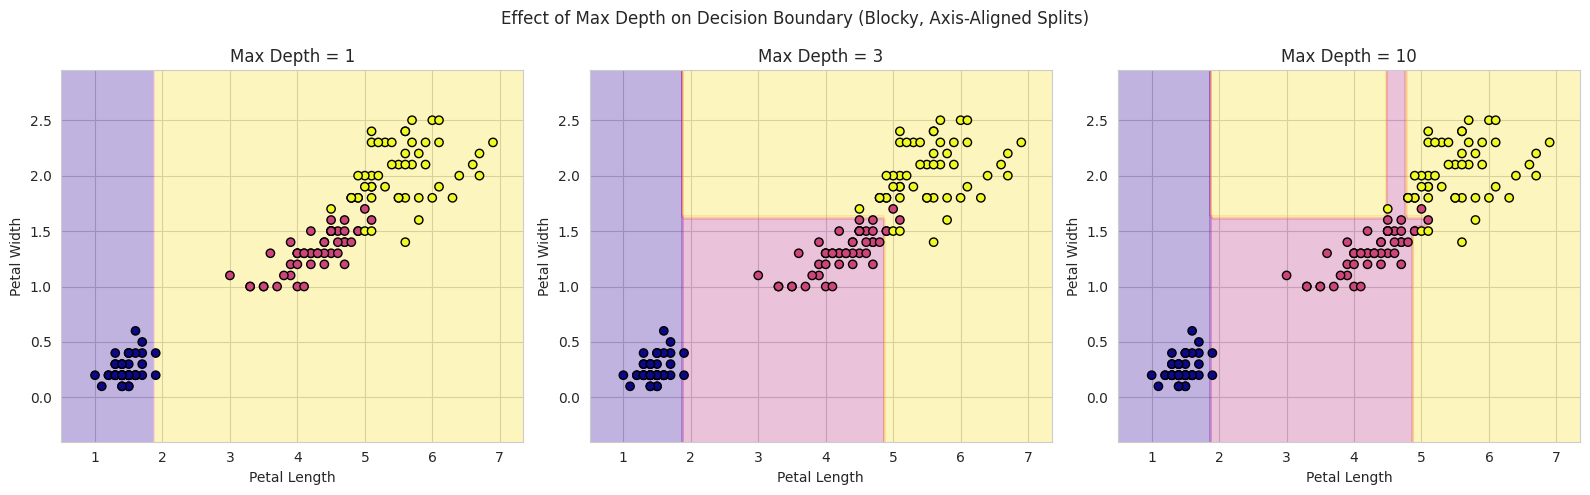

In [12]:
X2 = X[:, 2:4]  # petal length, petal width
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, d in zip(axes, [1, 3, 10]):
    tree2d = DecisionTreeScratch(max_depth=d)
    tree2d.fit(X2_train, y2_train)

    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                          np.arange(y_min, y_max, 0.05))

    Z = tree2d.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='plasma')
    ax.scatter(X2[:, 0], X2[:, 1], c=y, cmap='plasma', edgecolors='k')
    ax.set_title(f"Max Depth = {d}")
    ax.set_xlabel("Petal Length")
    ax.set_ylabel("Petal Width")

plt.suptitle("Effect of Max Depth on Decision Boundary (Blocky, Axis-Aligned Splits)")
plt.tight_layout()
plt.show()

## 📌 Key Takeaways

- Decision Trees split data recursively by choosing the feature and threshold that **maximize Information Gain** (i.e. minimize impurity — Gini or Entropy).
- They **don't require feature scaling**, unlike Logistic Regression or KNN.
- Decision boundaries are always **axis-aligned rectangles** — this is a direct consequence of splitting on one feature at a time.
- Shallow trees (`low max_depth`) underfit; deep trees can perfectly fit training data but **overfit** badly and generalize poorly — this is clearly visible in the train-vs-test accuracy plot.
- Decision Trees are highly **interpretable** — the learned rules can be printed and understood directly, unlike KNN or Logistic Regression's weight vectors.

## 🔗 Next Steps
- Try `min_samples_leaf` and `max_features` as additional regularization options.
- Explore how a single Decision Tree can be unstable (small data changes → very different trees).
- Move on to **Random Forest**, which combines many Decision Trees to reduce overfitting and improve stability.